In [31]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("cleaned_global_water_consumption.csv")

# Menampilkan informasi awal dataset
print("Ukuran dataset:", df.shape)

print("\nNama kolom:")
print(df.columns.tolist())

print("\nLima baris pertama:")
display(df.head())

print("\nInformasi tipe data:")
df.info()

print("\nJumlah nilai kosong:")
print(df.isnull().sum())

print("\nJumlah data duplikat:", df.duplicated().sum())

print("\nStatistik deskriptif:")
display(df.describe(include="all").T)


Ukuran dataset: (500, 10)

Nama kolom:
['Country', 'Year', 'Total Water Consumption (Billion Cubic Meters)', 'Per Capita Water Use (Liters per Day)', 'Agricultural Water Use (%)', 'Industrial Water Use (%)', 'Household Water Use (%)', 'Rainfall Impact (Annual Precipitation in mm)', 'Groundwater Depletion Rate (%)', 'Water Scarcity Level']

Lima baris pertama:


,Country,Year,Total Water Consumption (Billion Cubic Meters),Per Capita Water Use (Liters per Day),Agricultural Water Use (%),Industrial Water Use (%),Household Water Use (%),Rainfall Impact (Annual Precipitation in mm),Groundwater Depletion Rate (%),Water Scarcity Level
0,Argentina,2000,481.490000,235.431429,48.550000,20.844286,30.100000,1288.698571,3.255714,Moderate
1,Argentina,2001,455.063000,299.551000,48.465000,26.943000,22.550000,1371.729000,3.120000,Moderate
2,Argentina,2002,482.749231,340.124615,50.375385,29.042308,23.349231,1590.305385,2.733846,Moderate
3,Argentina,2003,452.660000,326.756667,49.086667,30.476000,24.440000,1816.012667,2.708000,Moderate
4,Argentina,2004,634.566000,230.346000,38.670000,36.670000,23.924000,815.998000,1.902000,Moderate



Informasi tipe data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Country                                         500 non-null    object 
 1   Year                                            500 non-null    int64  
 2   Total Water Consumption (Billion Cubic Meters)  500 non-null    float64
 3   Per Capita Water Use (Liters per Day)           500 non-null    float64
 4   Agricultural Water Use (%)                      500 non-null    float64
 5   Industrial Water Use (%)                        500 non-null    float64
 6   Household Water Use (%)                         500 non-null    float64
 7   Rainfall Impact (Annual Precipitation in mm)    500 non-null    float64
 8   Groundwater Depletion Rate (%)                  500 non-null    float64
 9   Water Scarcity Level 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Country,500,20,Argentina,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,500.0,NaN,NaN,NaN,2012.0,7.218324,2000.0,2006.0,2012.0,2018.0,2024.0
Total Water Consumption (Billion Cubic Meters),500.0,NaN,NaN,NaN,501.22443,96.078937,129.636667,441.447385,502.197154,563.849594,798.418
Per Capita Water Use (Liters per Day),500.0,NaN,NaN,NaN,276.004782,42.669593,111.708333,250.225406,276.430556,300.22175,404.35
Agricultural Water Use (%),500.0,NaN,NaN,NaN,50.180829,5.566886,28.905,46.513611,50.318482,54.061964,66.52
Industrial Water Use (%),500.0,NaN,NaN,NaN,27.792837,4.36166,13.276667,25.018,27.648539,30.698333,43.583333
Household Water Use (%),500.0,NaN,NaN,NaN,24.832515,2.956135,13.668333,23.015355,25.071944,26.720167,34.202
Rainfall Impact (Annual Precipitation in mm),500.0,NaN,NaN,NaN,1544.8243,292.786579,700.23,1353.734583,1537.537724,1746.402425,2533.678
Groundwater Depletion Rate (%),500.0,NaN,NaN,NaN,2.573037,0.48063,1.3,2.235,2.555778,2.887202,4.322
Water Scarcity Level,500,3,Moderate,360,NaN,NaN,NaN,NaN,NaN,NaN,NaN


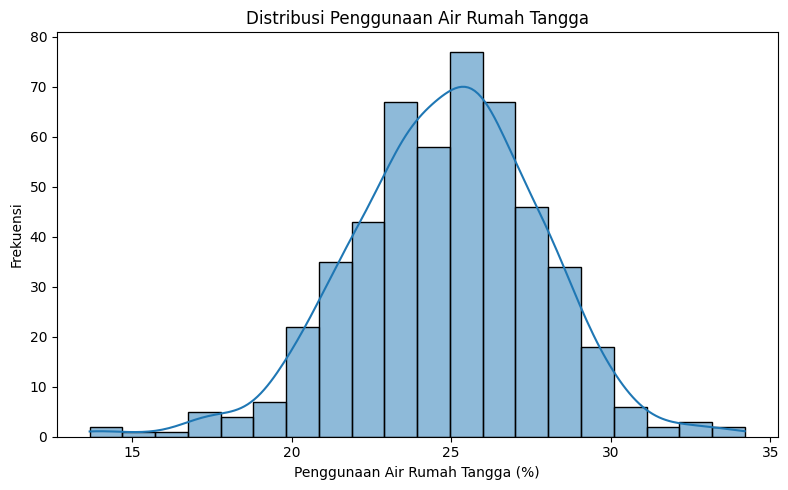

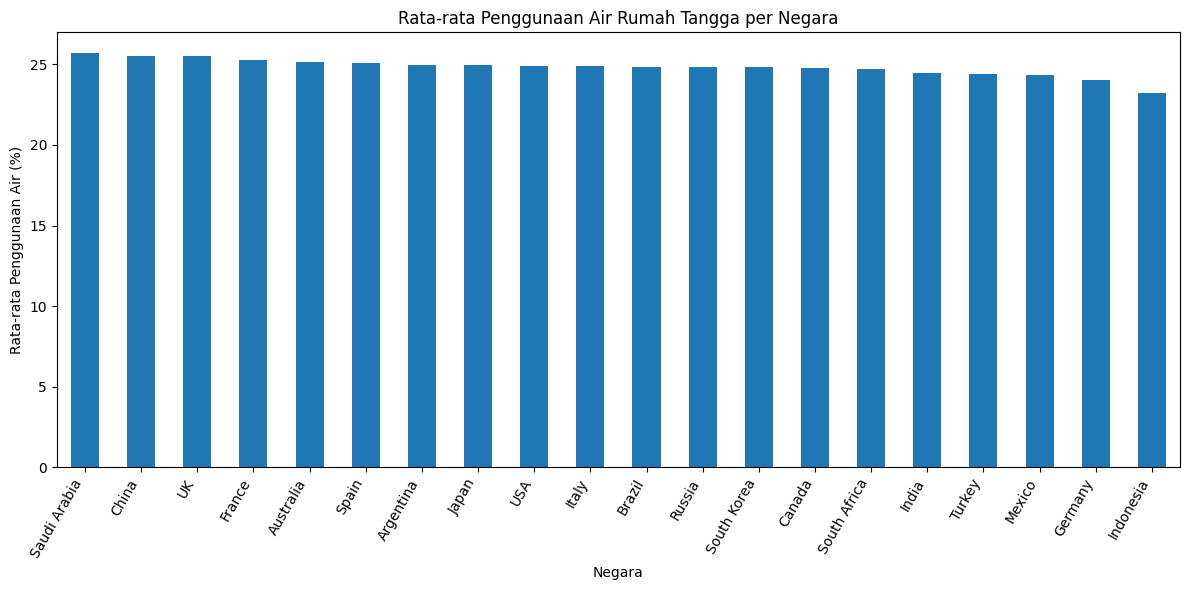

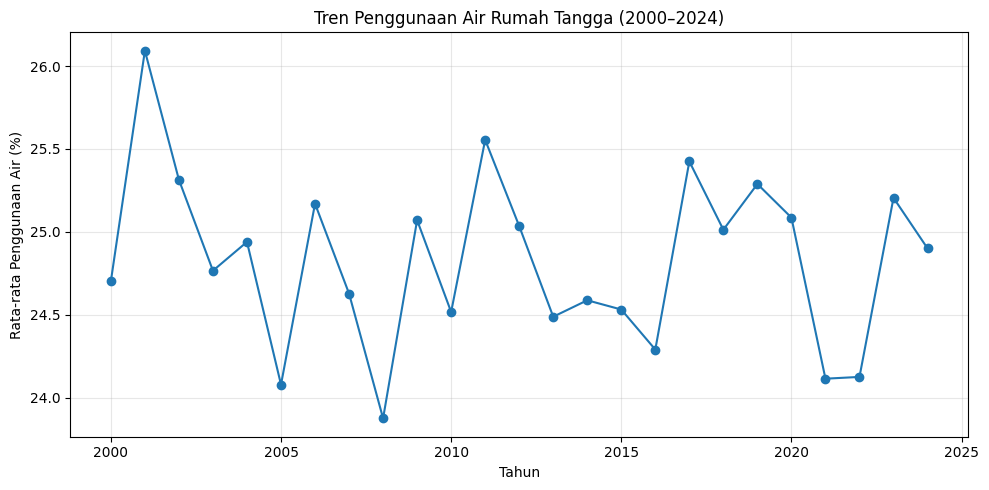

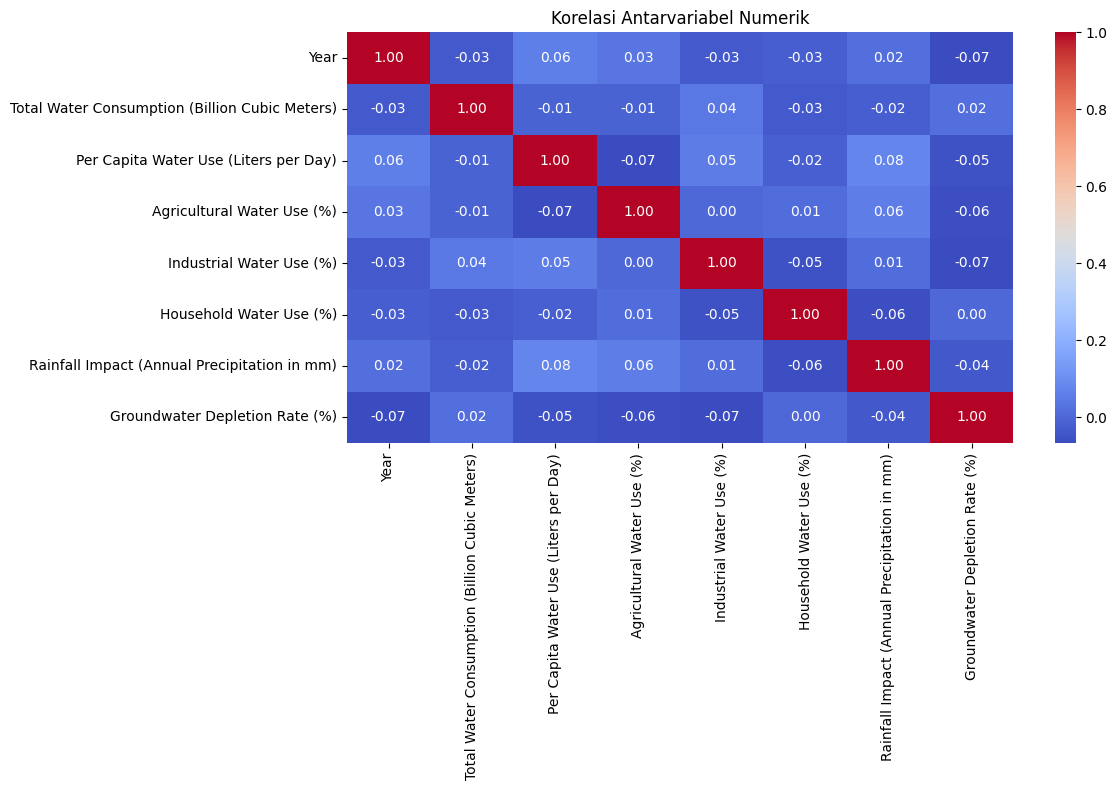

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Distribusi tingkat penggunaan air rumah tangga
plt.figure(figsize=(8, 5))
sns.histplot(
    data=df,
    x="Household Water Use (%)",
    bins=20,
    kde=True
)
plt.title("Distribusi Penggunaan Air Rumah Tangga")
plt.xlabel("Penggunaan Air Rumah Tangga (%)")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

# 2. Rata-rata penggunaan air rumah tangga per negara
household_country = (
    df.groupby("Country")["Household Water Use (%)"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))
household_country.plot(kind="bar")
plt.title("Rata-rata Penggunaan Air Rumah Tangga per Negara")
plt.xlabel("Negara")
plt.ylabel("Rata-rata Penggunaan Air (%)")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

# 3. Tren penggunaan air rumah tangga dari tahun ke tahun
household_year = (
    df.groupby("Year")["Household Water Use (%)"]
    .mean()
)

plt.figure(figsize=(10, 5))
household_year.plot(kind="line", marker="o")
plt.title("Tren Penggunaan Air Rumah Tangga (2000–2024)")
plt.xlabel("Tahun")
plt.ylabel("Rata-rata Penggunaan Air (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 4. Korelasi antarfitur numerik
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(12, 8))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Korelasi Antarvariabel Numerik")
plt.tight_layout()
plt.show()


In [33]:
# PREPROCESSING DATA

from sklearn.preprocessing import StandardScaler

# 1. Memilih fitur numerik yang relevan untuk clustering
fitur = [
    "Total Water Consumption (Billion Cubic Meters)",
    "Per Capita Water Use (Liters per Day)",
    "Agricultural Water Use (%)",
    "Industrial Water Use (%)",
    "Household Water Use (%)",
    "Rainfall Impact (Annual Precipitation in mm)",
    "Groundwater Depletion Rate (%)"
]

# 2. Membuat dataset fitur
X = df[fitur].copy()

# 3. Memeriksa nilai kosong dan data tidak valid
print("Jumlah nilai kosong per fitur:")
print(X.isnull().sum())

print("\nJumlah nilai tak hingga per fitur:")
print(np.isinf(X).sum())

# 4. Memastikan semua fitur numerik
X = X.apply(pd.to_numeric, errors="coerce")

# Menghapus baris yang mengandung nilai kosong atau tak hingga
valid = X.notna().all(axis=1) & np.isfinite(X).all(axis=1)
X = X.loc[valid].copy()

# Menyimpan identitas baris untuk analisis selanjutnya
df_cluster = df.loc[X.index].copy()

print("\nUkuran data setelah preprocessing:", X.shape)

# 5. Standardisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Mengubah hasil standardisasi menjadi DataFrame
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=fitur,
    index=X.index
)

print("\nLima baris pertama setelah standardisasi:")
display(X_scaled_df.head())

print("\nRata-rata fitur setelah standardisasi:")
display(X_scaled_df.mean().round(3))

print("\nStandar deviasi setelah standardisasi:")
display(X_scaled_df.std(ddof=0).round(3))


Jumlah nilai kosong per fitur:
Total Water Consumption (Billion Cubic Meters)    0
Per Capita Water Use (Liters per Day)             0
Agricultural Water Use (%)                        0
Industrial Water Use (%)                          0
Household Water Use (%)                           0
Rainfall Impact (Annual Precipitation in mm)      0
Groundwater Depletion Rate (%)                    0
dtype: int64

Jumlah nilai tak hingga per fitur:
Total Water Consumption (Billion Cubic Meters)    0
Per Capita Water Use (Liters per Day)             0
Agricultural Water Use (%)                        0
Industrial Water Use (%)                          0
Household Water Use (%)                           0
Rainfall Impact (Annual Precipitation in mm)      0
Groundwater Depletion Rate (%)                    0
dtype: int64

Ukuran data setelah preprocessing: (500, 7)

Lima baris pertama setelah standardisasi:


,Total Water Consumption (Billion Cubic Meters),Per Capita Water Use (Liters per Day),Agricultural Water Use (%),Industrial Water Use (%),Household Water Use (%),Rainfall Impact (Annual Precipitation in mm),Groundwater Depletion Rate (%)
0,-0.205604,-0.951825,-0.293245,-1.594693,1.783667,-0.875663,1.421802
1,-0.480934,0.552379,-0.308529,-0.195038,-0.772902,-0.591792,1.139152
2,-0.192484,1.504211,0.034984,0.286754,-0.502267,0.155494,0.334915
3,-0.505970,1.190607,-0.196745,0.615786,-0.132913,0.927160,0.281085
4,1.389223,-1.071126,-2.069803,2.037310,-0.307640,-2.491768,-1.397559



Rata-rata fitur setelah standardisasi:


Total Water Consumption (Billion Cubic Meters)   -0.0
Per Capita Water Use (Liters per Day)            -0.0
Agricultural Water Use (%)                       -0.0
Industrial Water Use (%)                         -0.0
Household Water Use (%)                          -0.0
Rainfall Impact (Annual Precipitation in mm)      0.0
Groundwater Depletion Rate (%)                   -0.0
dtype: float64


Standar deviasi setelah standardisasi:


Total Water Consumption (Billion Cubic Meters)    1.0
Per Capita Water Use (Liters per Day)             1.0
Agricultural Water Use (%)                        1.0
Industrial Water Use (%)                          1.0
Household Water Use (%)                           1.0
Rainfall Impact (Annual Precipitation in mm)      1.0
Groundwater Depletion Rate (%)                    1.0
dtype: float64

,Jumlah Cluster (k),Inertia,Silhouette Score
0,2,3124.3582,0.1029
1,3,2860.5943,0.1015
2,4,2682.1609,0.1017
3,5,2518.4507,0.1032
4,6,2396.7630,0.1038
5,7,2271.8475,0.1103
6,8,2175.0611,0.1080
7,9,2124.2342,0.1006
8,10,2053.4914,0.1084


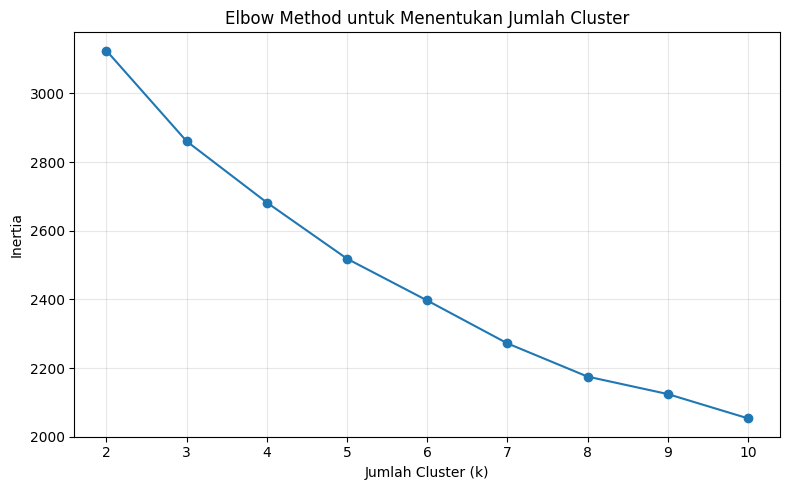

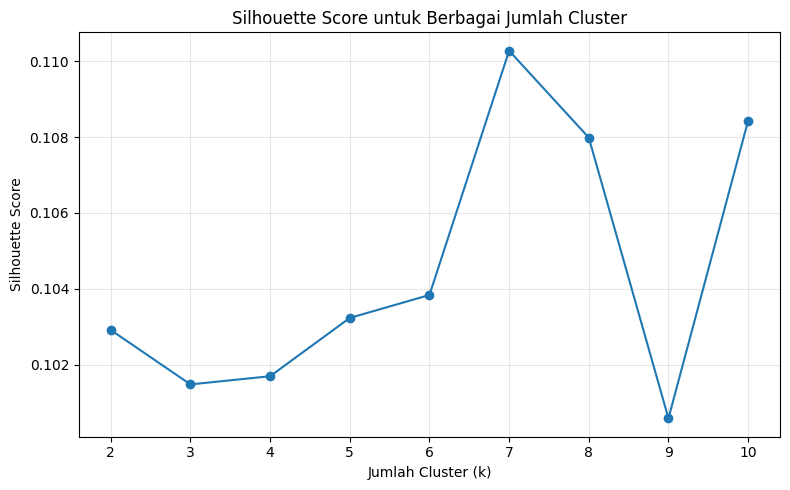

Kandidat jumlah cluster dengan Silhouette Score tertinggi: 7
Silhouette Score tertinggi: 0.1103


In [34]:
# ==========================================
# PERTEMUAN 3/5: EVALUASI JUMLAH CLUSTER
# ==========================================

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia_values = []
silhouette_values = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    inertia_values.append(model.inertia_)
    silhouette_values.append(
        silhouette_score(X_scaled, labels)
    )

# Menampilkan tabel evaluasi
hasil_k = pd.DataFrame({
    "Jumlah Cluster (k)": list(k_values),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_values
})

display(hasil_k.round(4))

# Grafik Elbow Method
plt.figure(figsize=(8, 5))
plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)
plt.title("Elbow Method untuk Menentukan Jumlah Cluster")
plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Grafik Silhouette Score
plt.figure(figsize=(8, 5))
plt.plot(
    list(k_values),
    silhouette_values,
    marker="o"
)
plt.title("Silhouette Score untuk Berbagai Jumlah Cluster")
plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Kandidat terbaik berdasarkan Silhouette Score
best_k = list(k_values)[
    int(np.argmax(silhouette_values))
]

print("Kandidat jumlah cluster dengan Silhouette Score tertinggi:", best_k)
print(
    "Silhouette Score tertinggi:",
    round(max(silhouette_values), 4)
)

,Algoritma,Jumlah Cluster,Silhouette Score
10,K-Means,7,0.1103
16,K-Means,10,0.1084
12,K-Means,8,0.1080
8,K-Means,6,0.1038
6,K-Means,5,0.1032
0,K-Means,2,0.1029
4,K-Means,4,0.1017
2,K-Means,3,0.1015
14,K-Means,9,0.1006
9,Agglomerative,6,0.0766


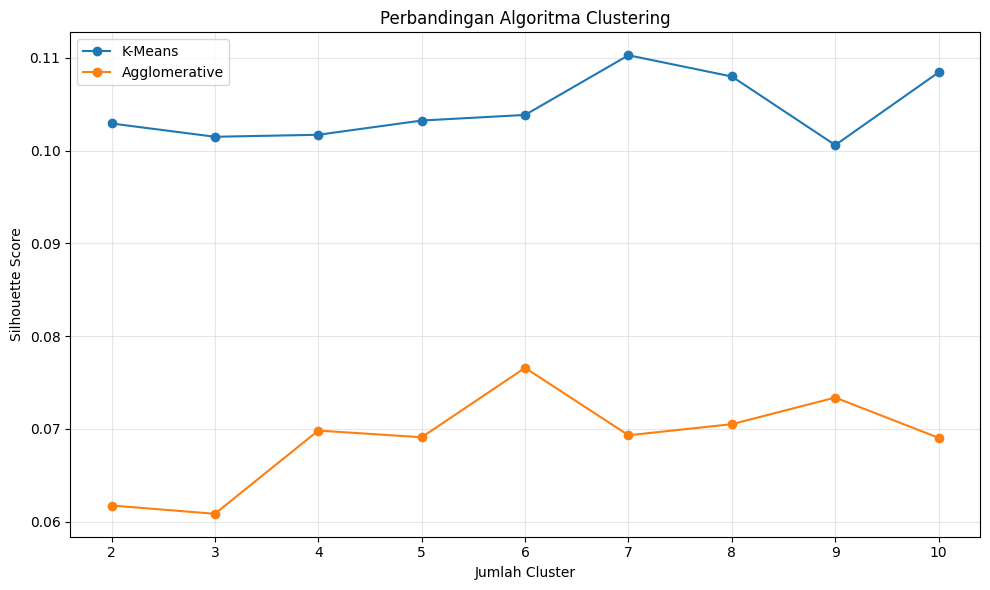

Kandidat model terbaik:
Algoritma            K-Means
Jumlah Cluster             7
Silhouette Score    0.110273


In [35]:
# PERBANDINGAN MODEL CLUSTERING

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

hasil_model = []

for k in range(2, 11):

    # Model K-Means
    model_kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    label_kmeans = model_kmeans.fit_predict(X_scaled)

    skor_kmeans = silhouette_score(X_scaled, label_kmeans)

    hasil_model.append({
        "Algoritma": "K-Means",
        "Jumlah Cluster": k,
        "Silhouette Score": skor_kmeans
    })

    # Model Agglomerative Clustering
    model_ag = AgglomerativeClustering(n_clusters=k)
    label_ag = model_ag.fit_predict(X_scaled)

    skor_ag = silhouette_score(X_scaled, label_ag)

    hasil_model.append({
        "Algoritma": "Agglomerative",
        "Jumlah Cluster": k,
        "Silhouette Score": skor_ag
    })

# Tabel perbandingan
hasil_perbandingan = pd.DataFrame(hasil_model)

display(
    hasil_perbandingan.sort_values(
        "Silhouette Score",
        ascending=False
    ).round(4)
)

# Grafik perbandingan
plt.figure(figsize=(10, 6))

for nama in hasil_perbandingan["Algoritma"].unique():
    subset = hasil_perbandingan[
        hasil_perbandingan["Algoritma"] == nama
    ]

    plt.plot(
        subset["Jumlah Cluster"],
        subset["Silhouette Score"],
        marker="o",
        label=nama
    )

plt.title("Perbandingan Algoritma Clustering")
plt.xlabel("Jumlah Cluster")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Kandidat terbaik dari model yang diuji
model_terbaik = hasil_perbandingan.loc[
    hasil_perbandingan["Silhouette Score"].idxmax()
]

print("Kandidat model terbaik:")
print(model_terbaik.to_string())

Algoritma final: K-Means
Jumlah cluster: 7
Silhouette Score: 0.1103

Jumlah anggota setiap cluster:


,Jumlah Data
Cluster,
0,62
1,91
2,73
3,73
4,72
5,53
6,76



Profil rata-rata fitur setiap cluster:


,Total Water Consumption (Billion Cubic Meters),Per Capita Water Use (Liters per Day),Agricultural Water Use (%),Industrial Water Use (%),Household Water Use (%),Rainfall Impact (Annual Precipitation in mm),Groundwater Depletion Rate (%)
Cluster,,,,,,,
0,427.58,324.30,48.48,31.23,24.18,1500.72,2.29
1,510.90,280.38,45.88,24.96,26.83,1717.93,2.56
2,502.65,252.69,52.73,31.26,24.26,1796.91,2.32
3,517.35,284.82,49.13,26.47,21.38,1639.64,2.99
4,406.29,251.99,52.37,24.35,25.83,1351.76,2.63
5,568.08,250.06,45.90,31.34,24.57,1255.34,2.77
6,576.17,286.13,56.18,27.12,26.07,1425.10,2.47



Ringkasan penggunaan air rumah tangga per cluster:


,count,mean,min,max
Cluster,,,,
0,62,24.18,13.82,30.14
1,91,26.83,22.04,33.60
2,73,24.26,19.92,29.45
3,73,21.38,13.67,25.65
4,72,25.83,19.90,34.20
5,53,24.57,18.66,30.50
6,76,26.07,21.02,31.20


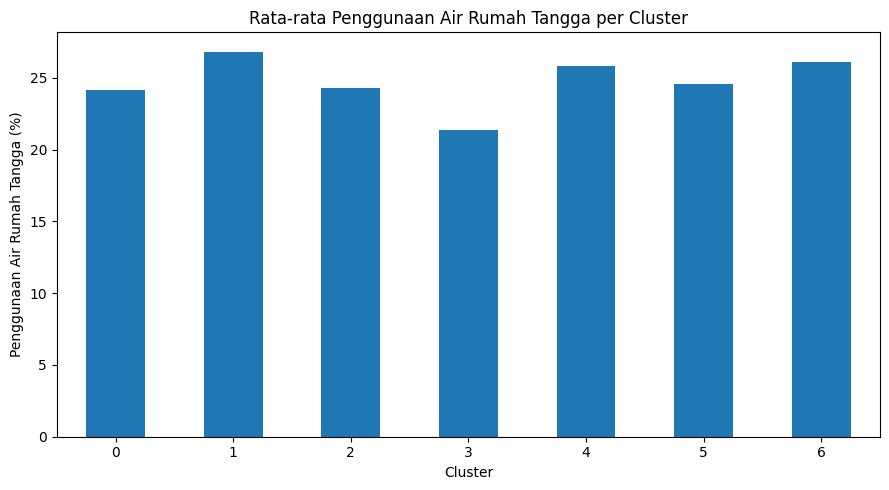

In [36]:
#MODEL FINAL DAN PROFIL CLUSTER

# Mengambil konfigurasi terbaik dari hasil perbandingan
algoritma_final = model_terbaik["Algoritma"]
k_final = int(model_terbaik["Jumlah Cluster"])

# Membuat model final
if algoritma_final == "K-Means":
    model_final = KMeans(
        n_clusters=k_final,
        random_state=42,
        n_init=10
    )
else:
    model_final = AgglomerativeClustering(
        n_clusters=k_final
    )

# Melatih model dan menghasilkan label cluster
label_final = model_final.fit_predict(X_scaled)

# Menambahkan label ke data asli
hasil_cluster = df_cluster.copy()
hasil_cluster["Cluster"] = label_final

print("Algoritma final:", algoritma_final)
print("Jumlah cluster:", k_final)
print(
    "Silhouette Score:",
    round(model_terbaik["Silhouette Score"], 4)
)

# 1. Jumlah anggota setiap cluster
print("\nJumlah anggota setiap cluster:")
display(
    hasil_cluster["Cluster"]
    .value_counts()
    .sort_index()
    .rename("Jumlah Data")
    .to_frame()
)

# 2. Profil rata-rata fitur setiap cluster
profil_cluster = (
    hasil_cluster.groupby("Cluster")[fitur]
    .mean()
    .round(2)
)

print("\nProfil rata-rata fitur setiap cluster:")
display(profil_cluster)

# 3. Analisis penggunaan air rumah tangga per cluster
print("\nRingkasan penggunaan air rumah tangga per cluster:")

ringkasan_rumah_tangga = (
    hasil_cluster.groupby("Cluster")[
        "Household Water Use (%)"
    ]
    .agg(["count", "mean", "min", "max"])
    .round(2)
)

display(ringkasan_rumah_tangga)

# 4. Visualisasi rata-rata penggunaan air rumah tangga
plt.figure(figsize=(9, 5))

profil_cluster["Household Water Use (%)"].plot(
    kind="bar"
)

plt.title("Rata-rata Penggunaan Air Rumah Tangga per Cluster")
plt.xlabel("Cluster")
plt.ylabel("Penggunaan Air Rumah Tangga (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [37]:
# VALIDASI KESTABILAN K-MEANS

from sklearn.metrics import adjusted_rand_score
from sklearn.cluster import KMeans

# Menggunakan jumlah cluster K-Means dengan skor tertinggi
hasil_kmeans = hasil_perbandingan[
    hasil_perbandingan["Algoritma"] == "K-Means"
]

baris_kmeans = hasil_kmeans.loc[
    hasil_kmeans["Silhouette Score"].idxmax()
]

k_validasi = int(baris_kmeans["Jumlah Cluster"])

# Label acuan
label_referensi = KMeans(
    n_clusters=k_validasi,
    random_state=42,
    n_init=10
).fit_predict(X_scaled)

# Menguji beberapa random state
hasil_stabilitas = []

for seed in [0, 21, 42, 100, 123]:

    model_uji = KMeans(
        n_clusters=k_validasi,
        random_state=seed,
        n_init=10
    )

    label_uji = model_uji.fit_predict(X_scaled)

    ari = adjusted_rand_score(
        label_referensi,
        label_uji
    )

    hasil_stabilitas.append({
        "Random State": seed,
        "Jumlah Cluster": k_validasi,
        "ARI": ari
    })

tabel_stabilitas = pd.DataFrame(hasil_stabilitas)

print("Hasil validasi kestabilan K-Means:")
display(tabel_stabilitas.round(4))

print(
    "\nRata-rata ARI:",
    round(tabel_stabilitas["ARI"].mean(), 4)
)

Hasil validasi kestabilan K-Means:


,Random State,Jumlah Cluster,ARI
0,0,7,0.2917
1,21,7,0.3717
2,42,7,1.0000
3,100,7,0.4837
4,123,7,0.3863



Rata-rata ARI: 0.5067


In [38]:
# EKSPOR HASIL CLUSTERING

# Simpan data beserta label cluster
nama_file = "hasil_clustering_B05_air_rumah_tangga.csv"

hasil_cluster.to_csv(
    nama_file,
    index=False
)

print("File hasil clustering berhasil disimpan:", nama_file)
print("Jumlah data:", len(hasil_cluster))
print("Jumlah cluster:", hasil_cluster["Cluster"].nunique())

File hasil clustering berhasil disimpan: hasil_clustering_B05_air_rumah_tangga.csv
Jumlah data: 500
Jumlah cluster: 7


Hasil setiap eksperimen:


,n_init,Random State,Inertia,Silhouette Score
15,100,0,2275.4332,0.1114
2,10,42,2271.8475,0.1103
7,25,42,2271.8475,0.1103
12,50,42,2271.8475,0.1103
17,100,42,2271.8475,0.1103
10,50,0,2275.9702,0.1093
9,25,123,2280.3400,0.1091
14,50,123,2280.3400,0.1091
6,25,21,2285.5890,0.1079
19,100,123,2277.3336,0.1074



Ringkasan berdasarkan jumlah inisialisasi:


,Rata_rata_Silhouette,Std_Silhouette,Rata_rata_Inertia,Silhouette_Tertinggi
n_init,,,,
10,0.1039,0.0040,2285.1738,0.1103
25,0.1082,0.0015,2280.5250,0.1103
50,0.1081,0.0022,2277.6466,0.1103
100,0.1084,0.0023,2275.4513,0.1114



Hasil kestabilan setiap konfigurasi:


,n_init,Random State,ARI terhadap seed 42
0,10,0,0.2917
1,10,21,0.3717
2,10,42,1.0000
3,10,100,0.4837
4,10,123,0.3863
5,25,0,0.4397
6,25,21,0.4515
7,25,42,1.0000
8,25,100,0.4006
9,25,123,0.3878



Rata-rata ARI per konfigurasi:


,ARI terhadap seed 42
n_init,
10,0.5067
25,0.5359
50,0.5126
100,0.5936


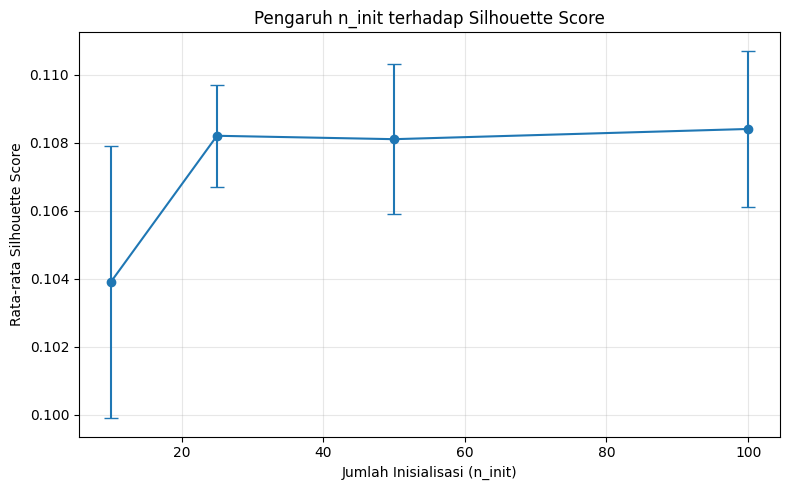

In [39]:
# LANGKAH 9: EKSPERIMEN K-MEANS
# Pengaruh jumlah inisialisasi (n_init)

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Gunakan 7 cluster agar perbandingan konsisten
k_eksperimen = 7

# Uji jumlah inisialisasi dan random state
daftar_n_init = [10, 25, 50, 100]
daftar_seed = [0, 21, 42, 100, 123]

hasil_eksperimen = []
label_per_seed = {}

for n_init in daftar_n_init:
    for seed in daftar_seed:

        model_uji = KMeans(
            n_clusters=k_eksperimen,
            random_state=seed,
            n_init=n_init
        )

        label_uji = model_uji.fit_predict(X_scaled)

        skor_silhouette = silhouette_score(
            X_scaled, label_uji
        )

        hasil_eksperimen.append({
            "n_init": n_init,
            "Random State": seed,
            "Inertia": model_uji.inertia_,
            "Silhouette Score": skor_silhouette
        })

        label_per_seed[(n_init, seed)] = label_uji

# Tabel hasil seluruh percobaan
tabel_eksperimen = pd.DataFrame(hasil_eksperimen)

print("Hasil setiap eksperimen:")
display(
    tabel_eksperimen.sort_values(
        "Silhouette Score", ascending=False
    ).round(4)
)

# Ringkasan kualitas model untuk setiap n_init
ringkasan_eksperimen = (
    tabel_eksperimen.groupby("n_init")
    .agg(
        Rata_rata_Silhouette=("Silhouette Score", "mean"),
        Std_Silhouette=("Silhouette Score", "std"),
        Rata_rata_Inertia=("Inertia", "mean"),
        Silhouette_Tertinggi=("Silhouette Score", "max")
    )
    .round(4)
)

print("\nRingkasan berdasarkan jumlah inisialisasi:")
display(ringkasan_eksperimen)

# Uji kestabilan: bandingkan label tiap seed
# dengan label seed 42 pada n_init yang sama
hasil_ari_eksperimen = []

for n_init in daftar_n_init:
    label_acuan = label_per_seed[(n_init, 42)]

    for seed in daftar_seed:
        ari = adjusted_rand_score(
            label_acuan,
            label_per_seed[(n_init, seed)]
        )

        hasil_ari_eksperimen.append({
            "n_init": n_init,
            "Random State": seed,
            "ARI terhadap seed 42": ari
        })

tabel_ari_eksperimen = pd.DataFrame(
    hasil_ari_eksperimen
)

print("\nHasil kestabilan setiap konfigurasi:")
display(tabel_ari_eksperimen.round(4))

print("\nRata-rata ARI per konfigurasi:")
display(
    tabel_ari_eksperimen.groupby("n_init")[
        "ARI terhadap seed 42"
    ].mean().round(4).to_frame()
)

# Grafik rata-rata Silhouette Score
plt.figure(figsize=(8, 5))
plt.errorbar(
    ringkasan_eksperimen.index,
    ringkasan_eksperimen["Rata_rata_Silhouette"],
    yerr=ringkasan_eksperimen["Std_Silhouette"],
    marker="o",
    capsize=5
)
plt.title("Pengaruh n_init terhadap Silhouette Score")
plt.xlabel("Jumlah Inisialisasi (n_init)")
plt.ylabel("Rata-rata Silhouette Score")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

ALGORITMA FINAL: K-MEANS
Jumlah cluster: 7
Random state: 0
n_init: 100
Inertia: 2275.4332
Silhouette Score: 0.1114

Jumlah anggota setiap cluster:


,Jumlah Data
Cluster,
0,80
1,80
2,82
3,75
4,76
5,59
6,48



Profil akhir setiap cluster:


,Total Water Consumption (Billion Cubic Meters),Per Capita Water Use (Liters per Day),Agricultural Water Use (%),Industrial Water Use (%),Household Water Use (%),Rainfall Impact (Annual Precipitation in mm),Groundwater Depletion Rate (%)
Cluster,,,,,,,
0,613.16,283.51,51.36,27.02,26.25,1394.11,2.34
1,449.88,248.82,55.39,25.07,24.82,1427.65,2.51
2,440.54,283.69,46.43,25.30,27.37,1532.76,2.86
3,523.49,289.73,48.07,26.02,21.04,1616.63,2.77
4,516.46,274.25,51.76,29.41,25.16,1937.92,2.50
5,417.86,300.52,50.87,32.36,24.27,1519.18,2.15
6,547.47,246.88,45.90,32.48,24.25,1308.85,2.90


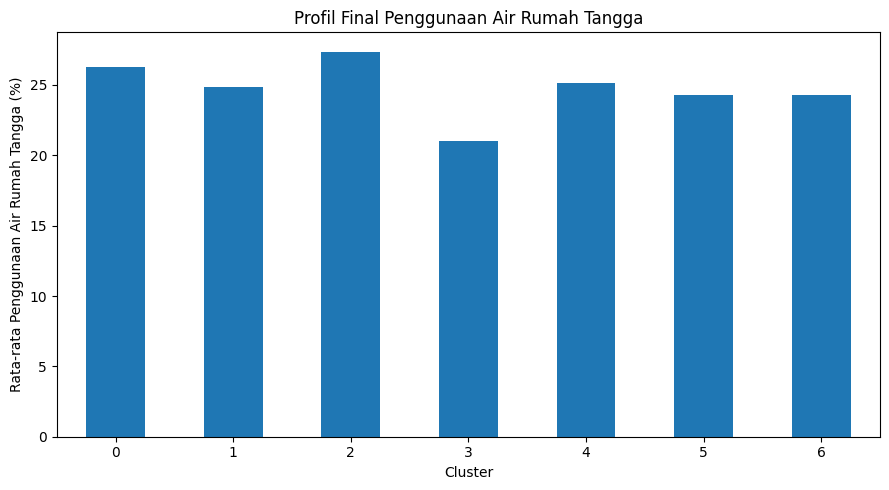

In [40]:
# MODEL FINAL HASIL EKSPERIMEN

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Konfigurasi terbaik berdasarkan eksperimen yang diuji
model_final_eksperimen = KMeans(
    n_clusters=7,
    random_state=0,
    n_init=100
)

label_final_eksperimen = model_final_eksperimen.fit_predict(
    X_scaled
)

skor_final = silhouette_score(
    X_scaled,
    label_final_eksperimen
)

print("ALGORITMA FINAL: K-MEANS")
print("Jumlah cluster:", 7)
print("Random state:", 0)
print("n_init:", 100)
print("Inertia:", round(model_final_eksperimen.inertia_, 4))
print("Silhouette Score:", round(skor_final, 4))

# Memperbarui label cluster pada dataset
hasil_cluster_final = df_cluster.copy()
hasil_cluster_final["Cluster"] = label_final_eksperimen

# Jumlah anggota cluster
print("\nJumlah anggota setiap cluster:")
display(
    hasil_cluster_final["Cluster"]
    .value_counts()
    .sort_index()
    .rename("Jumlah Data")
    .to_frame()
)

# Profil fitur setiap cluster
profil_final = (
    hasil_cluster_final.groupby("Cluster")[fitur]
    .mean()
    .round(2)
)

print("\nProfil akhir setiap cluster:")
display(profil_final)

# Visualisasi penggunaan air rumah tangga
plt.figure(figsize=(9, 5))

profil_final["Household Water Use (%)"].plot(
    kind="bar"
)

plt.title("Profil Final Penggunaan Air Rumah Tangga")
plt.xlabel("Cluster")
plt.ylabel("Rata-rata Penggunaan Air Rumah Tangga (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [41]:
# LANGKAH 11: VALIDASI MODEL FINAL

from sklearn.metrics import adjusted_rand_score

# Label acuan dari model final
label_acuan = label_final_eksperimen

hasil_validasi_final = []

for seed in [21, 42, 100, 123, 2026]:

    model_uji = KMeans(
        n_clusters=7,
        random_state=seed,
        n_init=100
    )

    label_uji = model_uji.fit_predict(X_scaled)

    ari = adjusted_rand_score(
        label_acuan,
        label_uji
    )

    hasil_validasi_final.append({
        "Random State": seed,
        "n_init": 100,
        "ARI terhadap model final": ari,
        "Silhouette Score": silhouette_score(
            X_scaled, label_uji
        )
    })

tabel_validasi_final = pd.DataFrame(
    hasil_validasi_final
)

display(tabel_validasi_final.round(4))

print(
    "Rata-rata ARI terhadap model final:",
    round(
        tabel_validasi_final[
            "ARI terhadap model final"
        ].mean(),
        4
    )
)

,Random State,n_init,ARI terhadap model final,Silhouette Score
0,21,100,0.4375,0.1062
1,42,100,0.3612,0.1103
2,100,100,0.3184,0.1066
3,123,100,0.4673,0.1074
4,2026,100,0.4627,0.1071


Rata-rata ARI terhadap model final: 0.4094


In [42]:
# LANGKAH 12: EKSPOR DATA MODEL FINAL

# Membuat file hasil akhir dengan label model final
nama_file_final = "hasil_final_clustering_B05.csv"

hasil_cluster_final.to_csv(
    nama_file_final,
    index=False
)

print("Ekspor model final berhasil.")
print("Nama file:", nama_file_final)
print("Jumlah observasi:", len(hasil_cluster_final))
print(
    "Jumlah cluster:",
    hasil_cluster_final["Cluster"].nunique()
)
print("Silhouette Score:", round(skor_final, 4))
print("Random state: 0")
print("n_init: 100")

Ekspor model final berhasil.
Nama file: hasil_final_clustering_B05.csv
Jumlah observasi: 500
Jumlah cluster: 7
Silhouette Score: 0.1114
Random state: 0
n_init: 100


In [43]:
# LANGKAH 13: RINGKASAN HASIL PROJECT

ringkasan_project = pd.DataFrame({
    "Aspek": [
        "Topik",
        "Metode utama",
        "Jumlah observasi",
        "Jumlah fitur clustering",
        "Jumlah cluster final",
        "Random state final",
        "n_init final",
        "Silhouette Score final",
        "Rata-rata ARI validasi final",
        "Algoritma pembanding"
    ],
    "Hasil": [
        "Pola Penggunaan Air Rumah Tangga",
        "Unsupervised Learning - Clustering",
        len(X_scaled),
        len(fitur),
        7,
        0,
        100,
        round(skor_final, 4),
        round(
            tabel_validasi_final[
                "ARI terhadap model final"
            ].mean(), 4
        ),
        "Agglomerative Clustering"
    ]
})

display(ringkasan_project)

,Aspek,Hasil
0,Topik,Pola Penggunaan Air Rumah Tangga
1,Metode utama,Unsupervised Learning - Clustering
2,Jumlah observasi,500
3,Jumlah fitur clustering,7
4,Jumlah cluster final,7
5,Random state final,0
6,n_init final,100
7,Silhouette Score final,0.1114
8,Rata-rata ARI validasi final,0.4094
9,Algoritma pembanding,Agglomerative Clustering


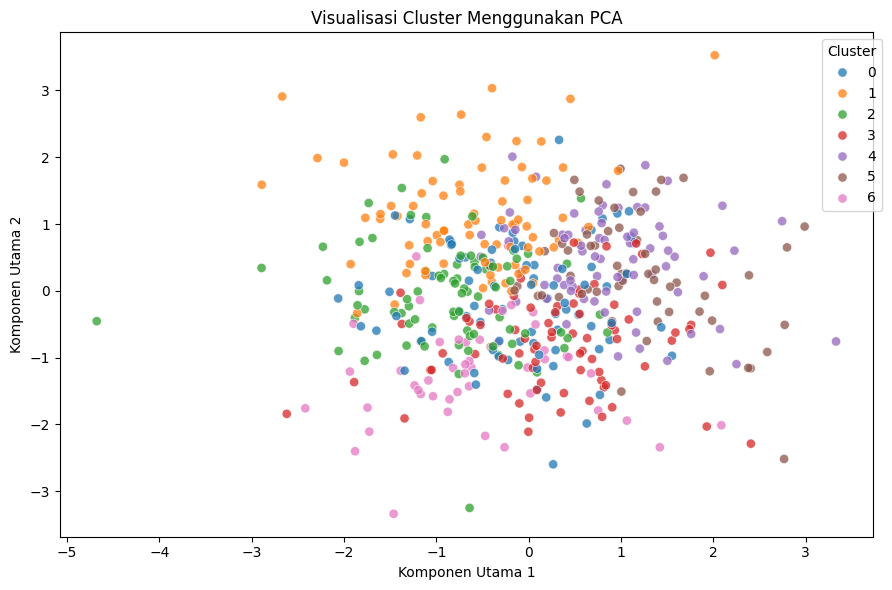

Variansi yang dijelaskan dua komponen PCA: 0.3238


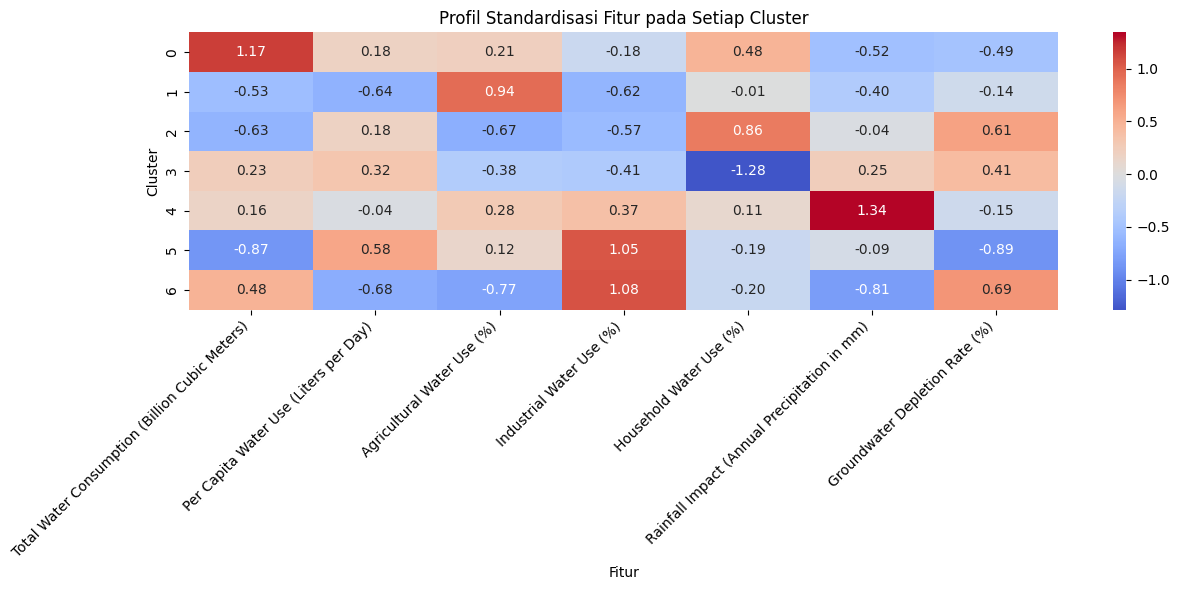

Kualitas setiap cluster:


,Jumlah_Data,Rata_rata_Silhouette,Silhouette_Minimum,Persentase_Silhouette_Negatif
Cluster,,,,
0,80,0.1116,-0.0145,2.5000
1,80,0.1201,0.0106,0.0000
2,82,0.1068,-0.0125,2.4390
3,75,0.0906,-0.0248,8.0000
4,76,0.1266,0.0214,0.0000
5,59,0.0993,-0.0324,8.4746
6,48,0.1275,-0.0194,6.2500



Silhouette Score keseluruhan: 0.1114


In [44]:
# LANGKAH 14: ANALISIS MENDALAM CLUSTER


from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_samples, silhouette_score
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Memastikan label yang dianalisis berasal dari model final
labels_final = hasil_cluster_final["Cluster"].to_numpy()

# 1. VISUALISASI PCA 2 DIMENSI
# PCA hanya untuk visualisasi, bukan melatih ulang clustering
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"],
    index=df_cluster.index
)
pca_df["Cluster"] = labels_final

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="tab10",
    alpha=0.75,
    s=45
)
plt.title("Visualisasi Cluster Menggunakan PCA")
plt.xlabel("Komponen Utama 1")
plt.ylabel("Komponen Utama 2")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

print(
    "Variansi yang dijelaskan dua komponen PCA:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

# 2. PROFIL FITUR DALAM SKALA STANDARDISASI
# Nilai positif berarti di atas rata-rata keseluruhan
profil_scaled = X_scaled_df.copy()
profil_scaled["Cluster"] = labels_final

profil_scaled_mean = (
    profil_scaled.groupby("Cluster")[fitur].mean()
)

plt.figure(figsize=(13, 6))
sns.heatmap(
    profil_scaled_mean,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f"
)
plt.title("Profil Standardisasi Fitur pada Setiap Cluster")
plt.xlabel("Fitur")
plt.ylabel("Cluster")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# 3. KUALITAS MASING-MASING CLUSTER
silhouette_individu = silhouette_samples(X_scaled, labels_final)

evaluasi_cluster = pd.DataFrame({
    "Cluster": labels_final,
    "Silhouette Individu": silhouette_individu
}, index=df_cluster.index)

ringkasan_kualitas = (
    evaluasi_cluster.groupby("Cluster")
    .agg(
        Jumlah_Data=("Silhouette Individu", "size"),
        Rata_rata_Silhouette=("Silhouette Individu", "mean"),
        Silhouette_Minimum=("Silhouette Individu", "min"),
        Persentase_Silhouette_Negatif=(
            "Silhouette Individu",
            lambda x: (x < 0).mean() * 100
        )
    )
    .round(4)
)

print("Kualitas setiap cluster:")
display(ringkasan_kualitas)

print(
    "\nSilhouette Score keseluruhan:",
    round(silhouette_score(X_scaled, labels_final), 4)
)

In [45]:
# LANGKAH 15: DOKUMENTASI EKSPERIMEN

dokumentasi = pd.DataFrame([
    ["Topik", "Pola Penggunaan Air Rumah Tangga"],
    ["Sumber dataset", "Kaggle: Global Water Consumption Dataset 2000-2024"],
    ["Jumlah observasi", len(X_scaled)],
    ["Jumlah fitur clustering", len(fitur)],
    ["Fitur", ", ".join(fitur)],
    ["Preprocessing", "StandardScaler"],
    ["Algoritma final", "K-Means"],
    ["Jumlah cluster", 7],
    ["Random state final", 0],
    ["n_init final", 100],
    ["Inertia final", round(model_final_eksperimen.inertia_, 4)],
    ["Silhouette Score final", round(skor_final, 4)],
    ["Rata-rata ARI validasi", round(
        tabel_validasi_final["ARI terhadap model final"].mean(), 4
    )],
    ["Algoritma pembanding", "Agglomerative Clustering"],
    ["Keterbatasan", (
        "Silhouette rendah; kestabilan cluster masih terbatas; "
        "data bersifat agregat negara-tahun, bukan rumah tangga individual."
    )]
], columns=["Aspek", "Keterangan"])

display(dokumentasi)

dokumentasi.to_csv(
    "dokumentasi_eksperimen_B05.csv",
    index=False
)

print("Dokumentasi eksperimen berhasil disimpan.")

,Aspek,Keterangan
0,Topik,Pola Penggunaan Air Rumah Tangga
1,Sumber dataset,Kaggle: Global Water Consumption Dataset 2000-...
2,Jumlah observasi,500
3,Jumlah fitur clustering,7
4,Fitur,Total Water Consumption (Billion Cubic Meters)...
5,Preprocessing,StandardScaler
6,Algoritma final,K-Means
7,Jumlah cluster,7
8,Random state final,0
9,n_init final,100


Dokumentasi eksperimen berhasil disimpan.


In [46]:
# LANGKAH 16: EKSPOR DATA FINAL TERBARU

nama_file_final = "hasil_final_clustering_B05.csv"

hasil_cluster_final.to_csv(
    nama_file_final,
    index=False
)

# Verifikasi file dengan membacanya kembali
verifikasi = pd.read_csv(nama_file_final)

print("Jumlah baris:", len(verifikasi))
print("Kolom cluster tersedia:", "Cluster" in verifikasi.columns)
print(
    "Jumlah cluster:",
    verifikasi["Cluster"].nunique()
)
print(
    "Jumlah anggota per cluster:"
)
display(
    verifikasi["Cluster"]
    .value_counts()
    .sort_index()
    .rename("Jumlah Data")
    .to_frame()
)

Jumlah baris: 500
Kolom cluster tersedia: True
Jumlah cluster: 7
Jumlah anggota per cluster:


,Jumlah Data
Cluster,
0,80
1,80
2,82
3,75
4,76
5,59
6,48


In [47]:
# PEMERIKSAAN AKHIR FILE CSV

import pandas as pd

file_final = pd.read_csv("hasil_final_clustering_B05.csv")

print("Daftar kolom file final:")
print(file_final.columns.tolist())

print("\nLima baris pertama:")
display(file_final.head())

print("\nJumlah baris dan kolom:")
print(file_final.shape)

print("\nPemeriksaan kolom identitas:")
for kolom in ["Country", "Year", "Cluster"]:
    print(f"{kolom}: {'Ada' if kolom in file_final.columns else 'Tidak ada'}")

Daftar kolom file final:
['Country', 'Year', 'Total Water Consumption (Billion Cubic Meters)', 'Per Capita Water Use (Liters per Day)', 'Agricultural Water Use (%)', 'Industrial Water Use (%)', 'Household Water Use (%)', 'Rainfall Impact (Annual Precipitation in mm)', 'Groundwater Depletion Rate (%)', 'Water Scarcity Level', 'Cluster']

Lima baris pertama:


,Country,Year,Total Water Consumption (Billion Cubic Meters),Per Capita Water Use (Liters per Day),Agricultural Water Use (%),Industrial Water Use (%),Household Water Use (%),Rainfall Impact (Annual Precipitation in mm),Groundwater Depletion Rate (%),Water Scarcity Level,Cluster
0,Argentina,2000,481.490000,235.431429,48.550000,20.844286,30.100000,1288.698571,3.255714,Moderate,2
1,Argentina,2001,455.063000,299.551000,48.465000,26.943000,22.550000,1371.729000,3.120000,Moderate,3
2,Argentina,2002,482.749231,340.124615,50.375385,29.042308,23.349231,1590.305385,2.733846,Moderate,3
3,Argentina,2003,452.660000,326.756667,49.086667,30.476000,24.440000,1816.012667,2.708000,Moderate,4
4,Argentina,2004,634.566000,230.346000,38.670000,36.670000,23.924000,815.998000,1.902000,Moderate,6



Jumlah baris dan kolom:
(500, 11)

Pemeriksaan kolom identitas:
Country: Ada
Year: Ada
Cluster: Ada


In [48]:
# MEMBUAT DOKUMENTASI EKSPERIMEN B05

import pandas as pd

dokumentasi = pd.DataFrame([
    ["Topik", "Pola Penggunaan Air Rumah Tangga"],
    ["ID Topik", "B05"],
    ["Sumber Dataset", "Kaggle - Global Water Consumption Dataset 2000-2024"],
    ["Jumlah Observasi", 500],
    ["Jumlah Fitur Clustering", 7],
    ["Fitur", ", ".join(fitur)],
    ["Preprocessing", "StandardScaler"],
    ["Metode", "Unsupervised Learning - Clustering"],
    ["Algoritma Final", "K-Means"],
    ["Algoritma Pembanding", "Agglomerative Clustering"],
    ["Jumlah Cluster Final", 7],
    ["Random State Final", 0],
    ["n_init Final", 100],
    ["Inertia Final", round(model_final_eksperimen.inertia_, 4)],
    ["Silhouette Score Final", round(skor_final, 4)],
    ["Rata-rata ARI Validasi", round(
        tabel_validasi_final["ARI terhadap model final"].mean(), 4
    )],
    ["Keterbatasan", (
        "Silhouette Score rendah dan kestabilan hasil clustering "
        "masih terbatas. Data merupakan data agregat negara-tahun, "
        "bukan data rumah tangga individual."
    )]
], columns=["Aspek", "Keterangan"])

nama_dokumentasi = "dokumentasi_eksperimen_B05.csv"

dokumentasi.to_csv(nama_dokumentasi, index=False)

print("Dokumentasi eksperimen berhasil dibuat.")
print("Jumlah aspek:", len(dokumentasi))
print("Nama file:", nama_dokumentasi)

display(dokumentasi)

Dokumentasi eksperimen berhasil dibuat.
Jumlah aspek: 17
Nama file: dokumentasi_eksperimen_B05.csv


,Aspek,Keterangan
0,Topik,Pola Penggunaan Air Rumah Tangga
1,ID Topik,B05
2,Sumber Dataset,Kaggle - Global Water Consumption Dataset 2000...
3,Jumlah Observasi,500
4,Jumlah Fitur Clustering,7
5,Fitur,Total Water Consumption (Billion Cubic Meters)...
6,Preprocessing,StandardScaler
7,Metode,Unsupervised Learning - Clustering
8,Algoritma Final,K-Means
9,Algoritma Pembanding,Agglomerative Clustering


In [49]:
# PROFIL CLUSTER UNTUK INTERPRETASI AKHIR

print("Jumlah anggota setiap cluster:")
display(
    hasil_cluster_final["Cluster"]
    .value_counts()
    .sort_index()
    .rename("Jumlah Data")
    .to_frame()
)

print("\nProfil rata-rata fitur asli:")
display(
    hasil_cluster_final.groupby("Cluster")[fitur]
    .mean()
    .round(2)
)

print("\nRata-rata penggunaan air rumah tangga per cluster:")
display(
    hasil_cluster_final.groupby("Cluster")[
        "Household Water Use (%)"
    ]
    .agg(["count", "mean", "min", "max"])
    .round(2)
)

Jumlah anggota setiap cluster:


,Jumlah Data
Cluster,
0,80
1,80
2,82
3,75
4,76
5,59
6,48



Profil rata-rata fitur asli:


,Total Water Consumption (Billion Cubic Meters),Per Capita Water Use (Liters per Day),Agricultural Water Use (%),Industrial Water Use (%),Household Water Use (%),Rainfall Impact (Annual Precipitation in mm),Groundwater Depletion Rate (%)
Cluster,,,,,,,
0,613.16,283.51,51.36,27.02,26.25,1394.11,2.34
1,449.88,248.82,55.39,25.07,24.82,1427.65,2.51
2,440.54,283.69,46.43,25.30,27.37,1532.76,2.86
3,523.49,289.73,48.07,26.02,21.04,1616.63,2.77
4,516.46,274.25,51.76,29.41,25.16,1937.92,2.50
5,417.86,300.52,50.87,32.36,24.27,1519.18,2.15
6,547.47,246.88,45.90,32.48,24.25,1308.85,2.90



Rata-rata penggunaan air rumah tangga per cluster:


,count,mean,min,max
Cluster,,,,
0,80,26.25,21.02,31.20
1,80,24.82,19.90,34.20
2,82,27.37,23.74,33.60
3,75,21.04,13.67,24.43
4,76,25.16,20.01,29.85
5,59,24.27,13.82,30.14
6,48,24.25,20.04,29.13


In [50]:
# MEMERIKSA VARIABEL YANG TERSEDIA

print("Pemeriksaan variabel:")

for nama in ["hasil_cluster_final", "hasil_clustering_final",
             "hasil_cluster", "fitur", "X_scaled"]:

    print(nama, ":", nama in globals())

Pemeriksaan variabel:
hasil_cluster_final : True
hasil_clustering_final : False
hasil_cluster : True
fitur : True
X_scaled : True


MATRIKS KORELASI ANTARFITUR:


,Total Water Consumption (Billion Cubic Meters),Per Capita Water Use (Liters per Day),Agricultural Water Use (%),Industrial Water Use (%),Household Water Use (%),Rainfall Impact (Annual Precipitation in mm),Groundwater Depletion Rate (%)
Total Water Consumption (Billion Cubic Meters),1.000,-0.010,-0.012,0.042,-0.033,-0.025,0.020
Per Capita Water Use (Liters per Day),-0.010,1.000,-0.068,0.052,-0.018,0.077,-0.055
Agricultural Water Use (%),-0.012,-0.068,1.000,0.002,0.014,0.057,-0.062
Industrial Water Use (%),0.042,0.052,0.002,1.000,-0.051,0.014,-0.067
Household Water Use (%),-0.033,-0.018,0.014,-0.051,1.000,-0.062,0.003
Rainfall Impact (Annual Precipitation in mm),-0.025,0.077,0.057,0.014,-0.062,1.000,-0.037
Groundwater Depletion Rate (%),0.020,-0.055,-0.062,-0.067,0.003,-0.037,1.000


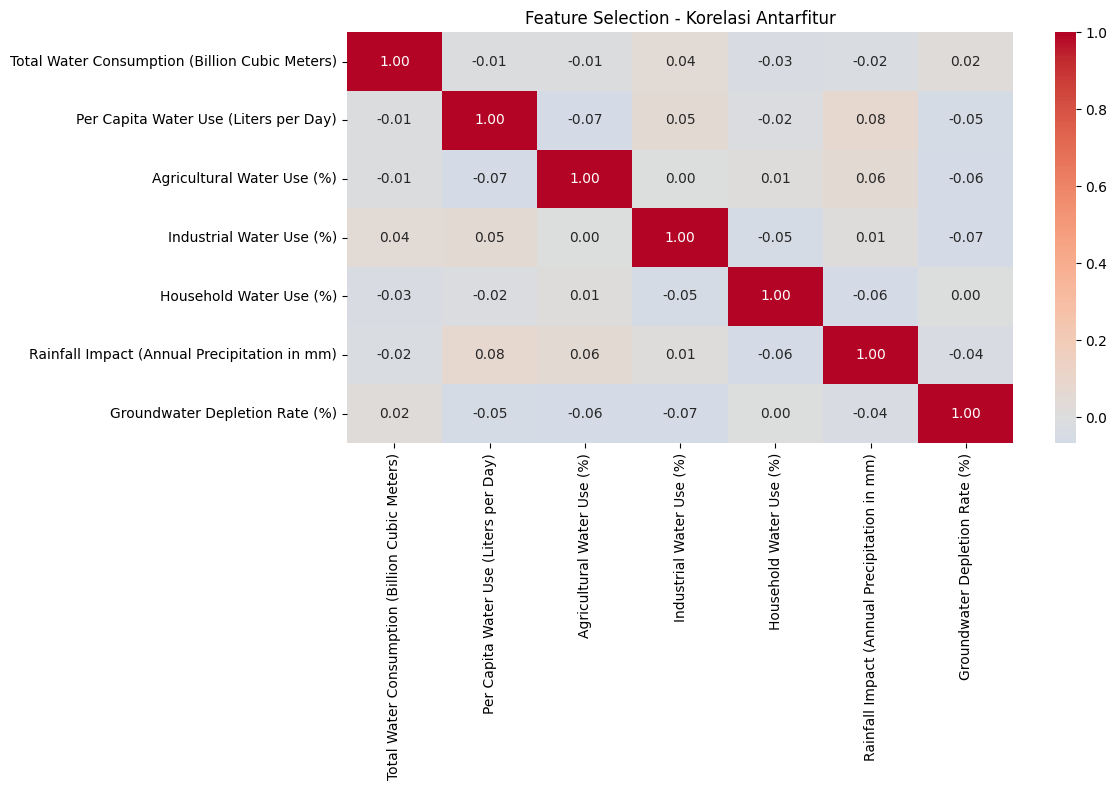


HASIL FEATURE SELECTION:


,Fitur,Alasan Pemilihan,Variansi
0,Total Water Consumption (Billion Cubic Meters),Menggambarkan total konsumsi air.,9231.1621
1,Per Capita Water Use (Liters per Day),Menggambarkan penggunaan air per kapita.,1820.6941
2,Agricultural Water Use (%),Menggambarkan penggunaan air pertanian.,30.9902
3,Industrial Water Use (%),Menggambarkan penggunaan air industri.,19.0241
4,Household Water Use (%),Menggambarkan penggunaan air rumah tangga.,8.7387
5,Rainfall Impact (Annual Precipitation in mm),Menggambarkan pengaruh curah hujan.,85723.9806
6,Groundwater Depletion Rate (%),Menggambarkan penurunan air tanah.,0.2310


Feature Selection berhasil disimpan.


In [51]:
# ==========================================
# LANGKAH 20: FEATURE SELECTION ANALYSIS
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Mengambil tujuh fitur yang digunakan
data_fitur = hasil_cluster_final[fitur].copy()

# Menghitung korelasi antarfitur
korelasi_fitur = data_fitur.corr()

print("MATRIKS KORELASI ANTARFITUR:")
display(korelasi_fitur.round(3))

# Visualisasi korelasi
plt.figure(figsize=(12, 8))

sns.heatmap(
    korelasi_fitur,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Feature Selection - Korelasi Antarfitur")
plt.tight_layout()
plt.show()

# Alasan pemilihan fitur
alasan_fitur = {
    fitur[0]: "Menggambarkan total konsumsi air.",
    fitur[1]: "Menggambarkan penggunaan air per kapita.",
    fitur[2]: "Menggambarkan penggunaan air pertanian.",
    fitur[3]: "Menggambarkan penggunaan air industri.",
    fitur[4]: "Menggambarkan penggunaan air rumah tangga.",
    fitur[5]: "Menggambarkan pengaruh curah hujan.",
    fitur[6]: "Menggambarkan penurunan air tanah."
}

# Membuat tabel seleksi fitur
tabel_seleksi = pd.DataFrame({
    "Fitur": fitur,
    "Alasan Pemilihan": [
        alasan_fitur[f] for f in fitur
    ],
    "Variansi": data_fitur.var().values
})

print("\nHASIL FEATURE SELECTION:")
display(tabel_seleksi.round(4))

# Menyimpan hasil
tabel_seleksi.to_csv(
    "feature_selection_B05.csv",
    index=False
)

print("Feature Selection berhasil disimpan.")

In [52]:
# LANGKAH 20A: FEATURE ENGINEERING
# Transformasi logaritmik pada fitur dengan nilai positif

import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Menggunakan data fitur asli
X_engineered = X.copy()

# Transformasi log1p pada dua fitur
fitur_transformasi = [
    "Total Water Consumption (Billion Cubic Meters)",
    "Rainfall Impact (Annual Precipitation in mm)"
]

for kolom in fitur_transformasi:
    if (X_engineered[kolom] < 0).any():
        raise ValueError(f"Nilai negatif ditemukan pada {kolom}")

    X_engineered[kolom] = np.log1p(X_engineered[kolom])

# Standardisasi ulang setelah transformasi
scaler_engineered = StandardScaler()
X_engineered_scaled = scaler_engineered.fit_transform(
    X_engineered
)

# Model K-Means dengan konfigurasi yang sama
model_engineered = KMeans(
    n_clusters=7,
    random_state=0,
    n_init=100
)

label_engineered = model_engineered.fit_predict(
    X_engineered_scaled
)

# Evaluasi hasil
skor_asli = silhouette_score(
    X_scaled,
    hasil_cluster_final["Cluster"]
)

skor_engineered = silhouette_score(
    X_engineered_scaled,
    label_engineered
)

ari_engineered = adjusted_rand_score(
    hasil_cluster_final["Cluster"],
    label_engineered
)

# Tabel perbandingan
perbandingan_feature = pd.DataFrame({
    "Eksperimen": [
        "Fitur Asli",
        "Fitur Setelah Log Transform"
    ],
    "Jumlah Fitur": [7, 7],
    "Silhouette Score": [
        skor_asli,
        skor_engineered
    ],
    "Inertia": [
        model_final_eksperimen.inertia_,
        model_engineered.inertia_
    ]
})

print("PERBANDINGAN FEATURE ENGINEERING:")
display(perbandingan_feature.round(4))

print(
    "\nARI antara cluster asli dan hasil transformasi:",
    round(ari_engineered, 4)
)

# Menyimpan hasil eksperimen
perbandingan_feature.to_csv(
    "feature_engineering_B05.csv",
    index=False
)

print("Feature Engineering berhasil disimpan.")


PERBANDINGAN FEATURE ENGINEERING:


,Eksperimen,Jumlah Fitur,Silhouette Score,Inertia
0,Fitur Asli,7,0.1114,2275.4332
1,Fitur Setelah Log Transform,7,0.1052,2249.2515



ARI antara cluster asli dan hasil transformasi: 0.2336
Feature Engineering berhasil disimpan.


In [53]:
# LANGKAH 20B: BASELINE DAN MODEL CANDIDATE

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

hasil_baseline = []

# 1. Baseline K-Means
baseline = KMeans(
    n_clusters=7,
    random_state=42,
    n_init=10
)

label_baseline = baseline.fit_predict(X_scaled)

hasil_baseline.append({
    "Model": "Baseline K-Means",
    "Jumlah Cluster": 7,
    "Silhouette Score": silhouette_score(
        X_scaled, label_baseline
    )
})

# 2. Candidate Agglomerative
candidate_ag = AgglomerativeClustering(
    n_clusters=7
)

label_ag = candidate_ag.fit_predict(X_scaled)

hasil_baseline.append({
    "Model": "Agglomerative Clustering",
    "Jumlah Cluster": 7,
    "Silhouette Score": silhouette_score(
        X_scaled, label_ag
    )
})

# 3. Final K-Means
hasil_baseline.append({
    "Model": "Final K-Means",
    "Jumlah Cluster": 7,
    "Silhouette Score": skor_asli
})

tabel_baseline = pd.DataFrame(hasil_baseline)

print("PERBANDINGAN BASELINE DAN MODEL KANDIDAT:")
display(tabel_baseline.round(4))

tabel_baseline.to_csv(
    "baseline_candidate_B05.csv",
    index=False
)

print("Perbandingan model berhasil disimpan.")


PERBANDINGAN BASELINE DAN MODEL KANDIDAT:


,Model,Jumlah Cluster,Silhouette Score
0,Baseline K-Means,7,0.1103
1,Agglomerative Clustering,7,0.0693
2,Final K-Means,7,0.1114


Perbandingan model berhasil disimpan.


In [54]:
# LANGKAH 20C: EVALUASI TEMPORAL
# Train: 2000-2019
# Test: 2020-2024

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Membagi data berdasarkan tahun
tahun = df_cluster["Year"]

idx_train = tahun <= 2019
idx_test = tahun >= 2020

X_train = X.loc[idx_train]
X_test = X.loc[idx_test]

# StandardScaler hanya belajar dari data training
scaler_temporal = StandardScaler()

X_train_scaled = scaler_temporal.fit_transform(X_train)
X_test_scaled = scaler_temporal.transform(X_test)

# Melatih model pada data training
model_temporal = KMeans(
    n_clusters=7,
    random_state=0,
    n_init=100
)

label_train = model_temporal.fit_predict(
    X_train_scaled
)

# Mengelompokkan data pengujian
label_test = model_temporal.predict(
    X_test_scaled
)

# Menghitung Silhouette Score
skor_train = silhouette_score(
    X_train_scaled,
    label_train
)

# Silhouette pada data test hanya dapat dihitung
# jika minimal ada dua cluster yang terwakili
if len(set(label_test)) >= 2:
    skor_test = silhouette_score(
        X_test_scaled,
        label_test
    )
else:
    skor_test = np.nan

# Membuat tabel hasil evaluasi
hasil_temporal = pd.DataFrame({
    "Data": ["Training 2000-2019", "Testing 2020-2024"],
    "Jumlah Observasi": [
        len(X_train),
        len(X_test)
    ],
    "Jumlah Cluster Terbentuk": [
        len(set(label_train)),
        len(set(label_test))
    ],
    "Silhouette Score": [
        skor_train,
        skor_test
    ]
})

print("HASIL EVALUASI TEMPORAL:")
display(hasil_temporal.round(4))

hasil_temporal.to_csv(
    "evaluasi_temporal_B05.csv",
    index=False
)

print("Evaluasi temporal berhasil disimpan.")


HASIL EVALUASI TEMPORAL:


,Data,Jumlah Observasi,Jumlah Cluster Terbentuk,Silhouette Score
0,Training 2000-2019,400,7,0.1139
1,Testing 2020-2024,100,7,0.0554


Evaluasi temporal berhasil disimpan.


In [55]:
print("hasil_cluster_final:", "hasil_cluster_final" in globals())
print("fitur:", "fitur" in globals())
print("X_scaled:", "X_scaled" in globals())

hasil_cluster_final: True
fitur: True
X_scaled: True


HASIL MODEL DIAGNOSIS:


,Jumlah_Data,Rata_rata_Silhouette,Silhouette_Minimum,Silhouette_Maksimum,Persentase_Negatif
Cluster,,,,,
0,80,0.1116,-0.0145,0.2805,2.5000
1,80,0.1201,0.0106,0.2891,0.0000
2,82,0.1068,-0.0125,0.2561,2.4390
3,75,0.0906,-0.0248,0.2713,8.0000
4,76,0.1266,0.0214,0.2712,0.0000
5,59,0.0993,-0.0324,0.2940,8.4746
6,48,0.1275,-0.0194,0.3390,6.2500


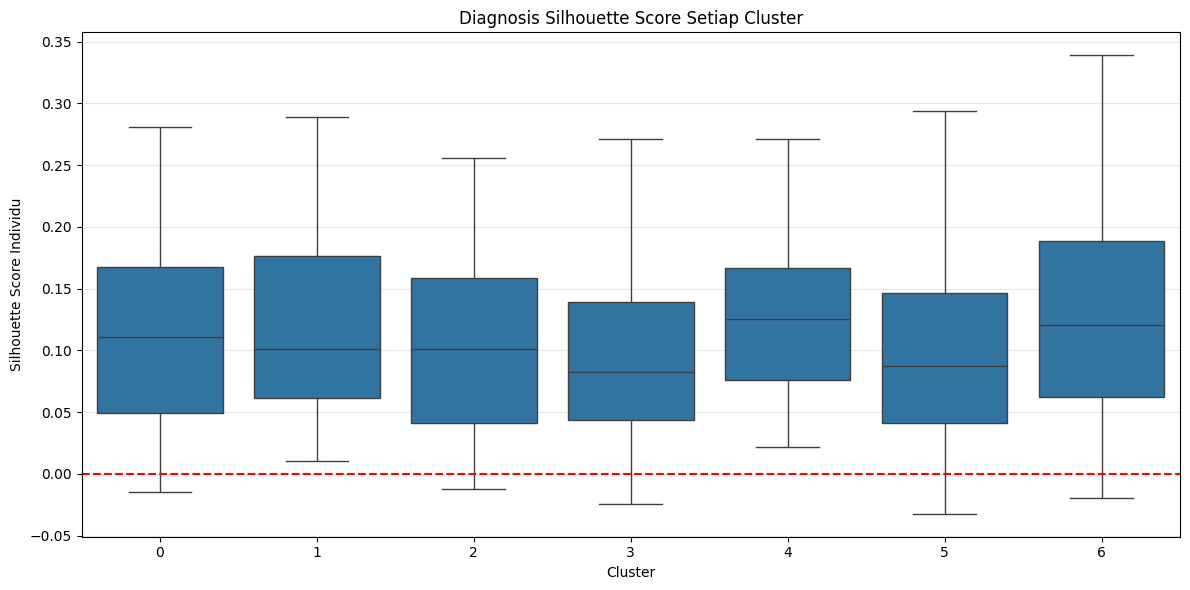

Hasil diagnosis berhasil disimpan.


In [56]:
# =====================================================
# LANGKAH 21: MODEL DIAGNOSIS
# =====================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import silhouette_samples

# Menghitung Silhouette Score setiap data
silhouette_individu = silhouette_samples(
    X_scaled,
    hasil_cluster_final["Cluster"]
)

# Membuat tabel diagnosis
diagnosis_model = pd.DataFrame({
    "Cluster": hasil_cluster_final["Cluster"].values,
    "Silhouette Individu": silhouette_individu
})

# Ringkasan kualitas setiap cluster
ringkasan_diagnosis = diagnosis_model.groupby("Cluster").agg(
    Jumlah_Data=("Silhouette Individu", "count"),
    Rata_rata_Silhouette=("Silhouette Individu", "mean"),
    Silhouette_Minimum=("Silhouette Individu", "min"),
    Silhouette_Maksimum=("Silhouette Individu", "max"),
    Persentase_Negatif=(
        "Silhouette Individu",
        lambda x: (x < 0).mean() * 100
    )
).round(4)

print("HASIL MODEL DIAGNOSIS:")
display(ringkasan_diagnosis)

# Visualisasi kualitas cluster
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=diagnosis_model,
    x="Cluster",
    y="Silhouette Individu"
)

plt.axhline(0, color="red", linestyle="--")
plt.title("Diagnosis Silhouette Score Setiap Cluster")
plt.xlabel("Cluster")
plt.ylabel("Silhouette Score Individu")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Menyimpan hasil diagnosis
ringkasan_diagnosis.to_csv(
    "model_diagnosis_B05.csv"
)

print("Hasil diagnosis berhasil disimpan.")

RINGKASAN ERROR ANALYSIS:


,Jumlah Data
Kategori,
Pemisahan Lemah,245
Cluster Kurang Jelas,220
Salah Penempatan Cluster,18
Pemisahan Relatif Baik,17



Persentase setiap kategori (%):


Kategori
Pemisahan Lemah             49.0
Cluster Kurang Jelas        44.0
Salah Penempatan Cluster     3.6
Pemisahan Relatif Baik       3.4
Name: proportion, dtype: float64

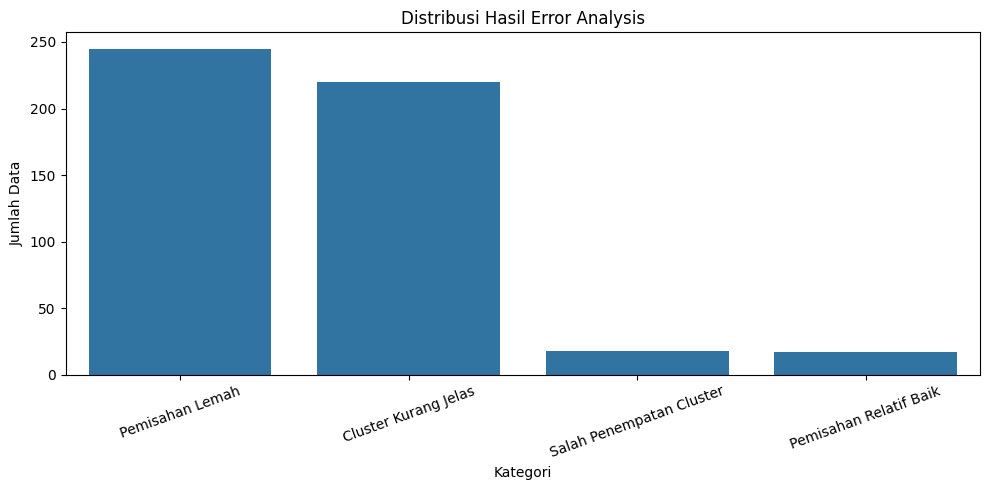


DATA YANG PERLU DIPERIKSA:


,Country,Year,Total Water Consumption (Billion Cubic Meters),Per Capita Water Use (Liters per Day),Agricultural Water Use (%),Industrial Water Use (%),Household Water Use (%),Rainfall Impact (Annual Precipitation in mm),Groundwater Depletion Rate (%),Water Scarcity Level,Cluster,Silhouette Score,Kategori
456,UK,2006,416.965000,313.617000,57.034000,31.292000,27.559000,1848.656000,2.260000,Low,5,-0.032396,Salah Penempatan Cluster
317,Russia,2017,382.332857,347.165714,52.410000,23.835714,23.548571,1864.070000,2.481429,Low,3,-0.024843,Salah Penempatan Cluster
418,Spain,2018,554.589091,249.585454,44.537273,30.848182,24.407273,1757.610909,2.732727,Moderate,6,-0.019380,Salah Penempatan Cluster
360,South Africa,2010,488.043333,242.853333,51.508889,31.596667,26.264444,1576.416667,2.123333,Moderate,5,-0.018618,Salah Penempatan Cluster
385,South Korea,2010,605.089000,231.141000,51.018000,25.201000,21.259000,1282.538000,2.503000,Moderate,3,-0.017946,Salah Penempatan Cluster
308,Russia,2008,608.366667,291.761111,47.813333,28.767778,21.516667,1761.913333,1.946667,Moderate,3,-0.016020,Salah Penempatan Cluster
82,Canada,2007,572.606667,270.127778,49.506667,28.005556,23.995556,1688.984444,1.990000,Moderate,0,-0.014483,Salah Penempatan Cluster
401,Spain,2001,364.055000,283.690000,43.610000,28.250000,33.595000,2280.900000,2.145000,Moderate,2,-0.012515,Salah Penempatan Cluster
139,France,2014,595.247500,204.920000,50.237500,31.242500,23.818333,1743.239167,2.814167,Moderate,6,-0.011852,Salah Penempatan Cluster
482,USA,2007,649.629167,287.130000,49.732500,26.387500,24.375000,1783.709167,3.150833,Moderate,3,-0.006514,Salah Penempatan Cluster



Error Analysis berhasil disimpan.


In [57]:
# =====================================================
# LANGKAH 22: ERROR ANALYSIS
# =====================================================

# Menggabungkan hasil clustering dan nilai silhouette
error_analysis = hasil_cluster_final.copy()

error_analysis["Silhouette Score"] = silhouette_individu

# Mengelompokkan kondisi data
def kategori_error(nilai):
    if nilai < 0:
        return "Salah Penempatan Cluster"
    elif nilai < 0.10:
        return "Cluster Kurang Jelas"
    elif nilai < 0.25:
        return "Pemisahan Lemah"
    else:
        return "Pemisahan Relatif Baik"

error_analysis["Kategori"] = (
    error_analysis["Silhouette Score"]
    .apply(kategori_error)
)

print("RINGKASAN ERROR ANALYSIS:")

display(
    error_analysis["Kategori"]
    .value_counts()
    .to_frame("Jumlah Data")
)

# Persentase setiap kategori
persentase_error = (
    error_analysis["Kategori"]
    .value_counts(normalize=True) * 100
)

print("\nPersentase setiap kategori (%):")
display(persentase_error.round(2))

# Visualisasi distribusi kategori
plt.figure(figsize=(10, 5))

sns.countplot(
    data=error_analysis,
    x="Kategori",
    order=error_analysis["Kategori"].value_counts().index
)

plt.title("Distribusi Hasil Error Analysis")
plt.xlabel("Kategori")
plt.ylabel("Jumlah Data")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Mengambil data yang perlu diperiksa
data_bermasalah = error_analysis[
    error_analysis["Silhouette Score"] < 0.10
].sort_values("Silhouette Score")

print("\nDATA YANG PERLU DIPERIKSA:")
display(data_bermasalah.head(15))

# Menyimpan hasil
error_analysis.to_csv(
    "error_analysis_B05.csv",
    index=False
)

print("\nError Analysis berhasil disimpan.")

In [58]:
# =====================================================
# LANGKAH 23: KESIMPULAN EVALUASI AKHIR
# =====================================================

# Ringkasan Feature Selection
jumlah_fitur = len(fitur)

# Ringkasan Model Diagnosis
rata_silhouette = silhouette_individu.mean()

# Ringkasan Error Analysis
jumlah_error = len(
    error_analysis[
        error_analysis["Silhouette Score"] < 0
    ]
)

persentase_error = (
    jumlah_error / len(error_analysis)
) * 100

# Membuat tabel evaluasi
evaluasi_akhir = pd.DataFrame({
    "Aspek Evaluasi": [
        "Feature Selection",
        "Jumlah Fitur Terpilih",
        "Model Diagnosis",
        "Rata-rata Silhouette",
        "Error Analysis",
        "Data Silhouette Negatif",
        "Persentase Data Silhouette Negatif",
        "Algoritma Final",
        "Jumlah Cluster"
    ],

    "Hasil": [
        "7 fitur numerik digunakan",
        jumlah_fitur,
        "Evaluasi kualitas cluster",
        round(rata_silhouette, 4),
        "Analisis pemisahan cluster",
        jumlah_error,
        round(persentase_error, 2),
        "K-Means",
        hasil_cluster_final["Cluster"].nunique()
    ]
})

print("HASIL EVALUASI AKHIR PROJECT B05:")
display(evaluasi_akhir)

# Menyimpan evaluasi akhir
evaluasi_akhir.to_csv(
    "evaluasi_akhir_B05.csv",
    index=False
)

print("Evaluasi akhir berhasil disimpan.")

HASIL EVALUASI AKHIR PROJECT B05:


,Aspek Evaluasi,Hasil
0,Feature Selection,7 fitur numerik digunakan
1,Jumlah Fitur Terpilih,7
2,Model Diagnosis,Evaluasi kualitas cluster
3,Rata-rata Silhouette,0.1114
4,Error Analysis,Analisis pemisahan cluster
5,Data Silhouette Negatif,18
6,Persentase Data Silhouette Negatif,3.6
7,Algoritma Final,K-Means
8,Jumlah Cluster,7


Evaluasi akhir berhasil disimpan.


In [59]:
# =====================================================
# LANGKAH 24: EKSPOR LAPORAN EVALUASI LENGKAP (PYTO)
# =====================================================

import os
import pandas as pd

nama_laporan = "Laporan_Lengkap_Project_B05.xlsx"

# Daftar sheet: (nama sheet, nama variabel, simpan index?)
daftar_sheet = [
    ("Hasil_Clustering",  "hasil_cluster_final", False),
    ("Feature_Selection", "tabel_seleksi",       False),
    ("Model_Diagnosis",   "ringkasan_diagnosis", True),
    ("Error_Analysis",    "error_analysis",      False),
    ("Evaluasi_Akhir",    "evaluasi_akhir",      False),
]

sheet_dilewati = []

with pd.ExcelWriter(nama_laporan) as writer:
    for nama_sheet, nama_var, pakai_index in daftar_sheet:
        data = globals().get(nama_var)
        if isinstance(data, (pd.DataFrame, pd.Series)):
            data.to_excel(writer, sheet_name=nama_sheet, index=pakai_index)
        else:
            sheet_dilewati.append(f"{nama_sheet} (variabel '{nama_var}' belum ada)")

path_laporan = os.path.abspath(nama_laporan)
print("Laporan lengkap berhasil dibuat:", path_laporan)

if sheet_dilewati:
    print("\nSheet yang dilewati:")
    for s in sheet_dilewati:
        print("-", s)

# Bagikan / simpan file lewat share sheet iOS (khusus Pyto)
try:
    import sharing
    sharing.share_items([path_laporan])
except ImportError:
    print("\nModul 'sharing' tidak tersedia. Buka file lewat aplikasi Files.")

Laporan lengkap berhasil dibuat: e:\UTS KELOMPOK 13\Laporan_Lengkap_Project_B05.xlsx

Modul 'sharing' tidak tersedia. Buka file lewat aplikasi Files.


Kesimpulan Akhir Project

Berdasarkan seluruh tahapan penelitian yang telah dilakukan, project dengan topik Pola Penggunaan Air Rumah Tangga berhasil menerapkan metode Unsupervised Learning menggunakan algoritma K-Means Clustering untuk mengelompokkan data berdasarkan karakteristik konsumsi dan penggunaan air.

Dataset yang digunakan terdiri dari 500 observasi yang mencakup data 20 negara selama periode 2000–2024. Sebelum proses clustering dilakukan, data melalui tahapan pemeriksaan kualitas, pemilihan tujuh fitur numerik, serta preprocessing menggunakan metode StandardScaler agar setiap fitur memiliki skala yang sebanding.

Berdasarkan hasil eksperimen dan perbandingan konfigurasi, model K-Means dipilih sebagai model akhir dengan tujuh cluster, random state 0, dan n_init 100. Model tersebut menghasilkan nilai Inertia sebesar 2275.4332 dan Silhouette Score sebesar 0.1114. Hasil validasi menggunakan beberapa random state menghasilkan rata-rata Adjusted Rand Index (ARI) sebesar 0.4094.

Analisis profil cluster menunjukkan adanya perbedaan karakteristik penggunaan air pada setiap kelompok, khususnya pada konsumsi air total, penggunaan air per kapita, penggunaan air untuk pertanian dan industri, penggunaan air rumah tangga, curah hujan, serta tingkat penurunan air tanah. Dengan demikian, clustering dapat digunakan untuk memberikan gambaran awal mengenai variasi pola penggunaan air berdasarkan karakteristik data.

Tahapan Feature Selection, Model Diagnosis, dan Error Analysis juga telah dilakukan untuk mengevaluasi kualitas hasil pengelompokan. Hasil diagnosis menunjukkan bahwa kualitas pemisahan cluster masih relatif rendah, dengan 18 data atau 3,6% memiliki nilai Silhouette negatif. Selain itu, analisis menunjukkan bahwa sebagian besar data masih memiliki pemisahan cluster yang lemah atau kurang jelas. Hal ini menunjukkan bahwa hasil clustering masih perlu ditingkatkan melalui pengujian algoritma, jumlah cluster, dan konfigurasi parameter lainnya.

Secara keseluruhan, project ini berhasil menyelesaikan proses pengolahan data, eksperimen clustering, evaluasi model, hingga dokumentasi hasil penelitian. Meskipun model K-Means telah menghasilkan tujuh kelompok dengan karakteristik yang berbeda, kualitas pemisahan cluster masih menjadi keterbatasan utama yang perlu diperhatikan.

Untuk pengembangan selanjutnya, penelitian dapat mencoba algoritma clustering lain, seperti Agglomerative Clustering atau DBSCAN, melakukan optimasi jumlah cluster, serta mengevaluasi penggunaan fitur yang lebih relevan.

Perlu diperhatikan bahwa dataset yang digunakan merupakan data agregat berdasarkan negara dan tahun, bukan data penggunaan air dari rumah tangga secara individual. Oleh karena itu, hasil penelitian ini lebih tepat digunakan untuk menggambarkan pola penggunaan air pada tingkat negara, bukan untuk menyimpulkan perilaku konsumsi setiap rumah tangga.